<div dir="rtl">

# هل عرض تقييمات المستخدمين بجانب المنتجات يزيد معدل الشراء؟

**برنامج التجارب واختبارات A/B والاستدلال السببي**، أكاديمية سدايا، نوفمبر 2026

| البند | القيمة |
|---|---|
| الاسم | جوهرة الملحم |
| المنتج | متجر إلكتروني: صفحة قائمة المنتجات ونتائج البحث |
| المشكلة | التقييمات لا تظهر إلا داخل صفحة المنتج، فلا يراها المستخدم وهو يقارن بين المنتجات |
| الهدف والقرار | هل نطلق عرض النجوم وعدد المراجعات بجانب كل منتج لكل المستخدمين؟ |

يعمل الدفتر من البداية للنهاية بالترتيب: **Runtime ← Run all**. الكود نفسه موجود كملفات بايثون في مجلد `src/` وملف `main.py`.

</div>

<div dir="rtl">

## 1. السؤال والفرضية

- **السؤال:** هل يؤدي عرض تقييمات المستخدمين بجانب المنتجات إلى زيادة نسبة الشراء؟
- **الفرضية:** إذا عرضنا التقييمات بجانب المنتجات، فسوف ترتفع نسبة الشراء، لأن التقييمات تعطي المشتري ثقة ودليلًا اجتماعيًا وتقلل تردده.
- **المعالجة:** عرض النجوم وعدد المراجعات في القائمة ونتائج البحث.
- **المجموعة المعالجة B:** ترى التقييمات. **المجموعة المقارنة A:** الوضع الحالي.
- **الأثر المتوقع:** زيادة لا تقل عن 0.6 نقطة مئوية في نسبة الشراء.
- **ما يغير رأينا:** فترة ثقة كلها أقل من 0.6 نقطة، أو تجاوز أحد مقاييس الحماية حده المسموح.

## 2. تصميم التجربة

| البند | القيمة |
|---|---|
| المجتمع المستهدف | المستخدمون الجدد الذين يدخلون المتجر خلال مدة التجربة |
| وحدة العشوأة | المستخدم، فيرى النسخة نفسها في كل زياراته |
| نسبة التوزيع | 50% / 50% |
| طريقة التوزيع | دالة تجزئة MD5 على (ملح ثابت + رقم المستخدم)، فالتوزيع ثابت وقابل للتكرار |
| المدة | 14 يومًا (تُحسب في القسم 4) |
| شرط SUTVA | قرار المستخدم لا يتأثر بما يراه غيره، والخطر المحدود مشاركة الأجهزة أو الروابط |

## 3. المقاييس

- **المقياس الرئيسي:** نسبة المستخدمين الذين أكملوا طلبًا.
- **مقاييس ثانوية:** الإيراد لكل مستخدم، وقيمة الطلب لمن طلب.
- **مقاييس الحماية (عدم الإضرار):** الربح لكل مستخدم (يجب ألا ينخفض)، والإلغاء (حد +1 نقطة)، والتواصل مع الدعم (حد +0.5 نقطة)، وزمن تحميل الصفحة (حد +100 ملي ثانية).

</div>

<div dir="rtl">

## الإعداد

تثبيت المكتبات واستيرادها، ثم كل الإعدادات في مكان واحد: افتراضات التصميم، وحدود الحماية، و"الحقيقة" المخفية في المحاكاة.

</div>

In [1]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "statsmodels", "arabic-reshaper", "python-bidi"], check=True)

import hashlib, json, math
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import Markdown, display
from matplotlib import ft2font
from scipy import stats
from scipy.optimize import brentq
from scipy.stats import chisquare, norm
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest

pd.set_option("display.precision", 4)

In [2]:
from pathlib import Path

ROOT = Path.cwd()
DATA_PATH = ROOT / "data" / "dataset.csv"
CHARTS_DIR = ROOT / "outputs" / "charts"
RESULTS_DIR = ROOT / "outputs" / "results"

# ---------------- التصميم: ما نعرفه أو نقدره قبل التجربة ----------------
DESIGN = {
    "baseline_rate": 0.06,      # نسبة الشراء الحالية (6% من المستخدمين يشترون)
    "mde_abs": 0.006,           # أصغر أثر يهمنا تجاريًا: 0.6 نقطة مئوية (+10% نسبيًا)
    "alpha": 0.05,              # مستوى الدلالة
    "power": 0.80,              # القوة الإحصائية
    "daily_users": 5_000,       # مستخدمون جدد يدخلون التجربة يوميًا
    "treatment_share": 0.50,    # 50% للنسخة B
    "salt": "reviews-exp-2026", # ملح دالة التجزئة المستخدمة في التوزيع
    "annual_users": 5_000 * 365,
}

# حدود مقاييس الحماية (عدم الإضرار): نرفض الإطلاق إذا تجاوزت فترة الثقة هذه الحدود
GUARDRAILS = {
    "profit":            {"label": "الربح لكل مستخدم (ريال)",   "bad": "down", "margin": 0.0},
    "cancelled":         {"label": "نسبة إلغاء الطلبات",        "bad": "up",   "margin": 0.010},
    "contacted_support": {"label": "نسبة التواصل مع الدعم",      "bad": "up",   "margin": 0.005},
    "page_load_ms":      {"label": "زمن تحميل الصفحة (ملي ثانية)", "bad": "up",   "margin": 100.0},
}

# ---------------- المحاكاة: "الحقيقة" التي لا يعرفها المحلل في الواقع ----------------
SIMULATION = {
    "seed": 42,
    "true_lift_abs": 0.007,         # الأثر الحقيقي للتقييمات على احتمال الشراء
    "novelty_extra": 0.25,          # زيادة مؤقتة في الأيام الأولى (فضول)
    "mobile_share": 0.70,
    "returning_share": 0.40,
    "order_value_median": 170,      # الوسيط بالريال
    "order_value_effect": 0.015,    # المشتري الواثق يختار منتجًا أغلى قليلًا (+1.5%)
    "margin": 0.25,                 # هامش الربح
    "cancel_rate": 0.06, "cancel_effect": -0.004,
    "support_rate": 0.03, "support_effect": 0.0,
    "load_ms_mean": 1200, "load_ms_mobile_extra": 300, "load_ms_effect": 40,
    "duplicate_share": 0.003,       # سجلات مكررة بسبب إعادة إرسال الأحداث
}

In [3]:
_NATIVE = hasattr(ft2font, "__libraqm_version__")
if not _NATIVE:
    import arabic_reshaper
    from bidi.algorithm import get_display


def ar(text):
    """يعيد النص العربي بالشكل والاتجاه الصحيحين داخل رسوم matplotlib."""
    text = str(text)
    return text if _NATIVE else get_display(arabic_reshaper.reshape(text))


def header(title):
    print("\n" + "=" * 70 + f"\n{title}\n" + "=" * 70)


def pct(x, d=2):
    return f"{x * 100:.{d}f}%"


def pts(x, d=2):
    """فرق نسبتين بالنقاط المئوية."""
    return f"{x * 100:+.{d}f} نقطة"

<div dir="rtl">

## 4. حجم العينة والمدة

نحسب حجم العينة بطريقتين: الصيغة اليدوية لمقارنة نسبتين، ثم نتحقق منها بمكتبة statsmodels (حجم الأثر h لكوهين). بعدها نحول العدد إلى أيام، ونقربها إلى أسابيع كاملة لأن سلوك الشراء يختلف بين أيام الأسبوع.

</div>

In [4]:
def sample_size_formula(p1, p2, alpha, power):
    """الصيغة اليدوية لمقارنة نسبتين (اختبار ذو طرفين)."""
    z = norm.ppf(1 - alpha / 2) + norm.ppf(power)
    return math.ceil(z ** 2 * (p1 * (1 - p1) + p2 * (1 - p2)) / (p2 - p1) ** 2)


def sample_size_statsmodels(p1, p2, alpha, power):
    """تحقق ثانٍ بمكتبة statsmodels باستخدام حجم الأثر h لكوهين."""
    h = abs(proportion_effectsize(p2, p1))
    return math.ceil(NormalIndPower().solve_power(effect_size=h, alpha=alpha, power=power, ratio=1.0))


def mde_for_n(p, n_per_group, alpha, power):
    z = norm.ppf(1 - alpha / 2) + norm.ppf(power)
    return z * math.sqrt(2 * p * (1 - p) / n_per_group)


def plan(design):
    p1 = design["baseline_rate"]
    p2 = p1 + design["mde_abs"]
    n_formula = sample_size_formula(p1, p2, design["alpha"], design["power"])
    n_sm = sample_size_statsmodels(p1, p2, design["alpha"], design["power"])
    n = max(n_formula, n_sm)
    raw_days = math.ceil(2 * n / design["daily_users"])
    days = math.ceil(raw_days / 7) * 7          # أسابيع كاملة لتغطية كل أيام الأسبوع
    n_expected = days * design["daily_users"] // 2
    return {
        "n_per_group_formula": n_formula,
        "n_per_group_statsmodels": n_sm,
        "n_per_group": n,
        "raw_days": raw_days,
        "days": days,
        "n_expected_per_group": n_expected,
        "mde_planned": mde_for_n(p1, n_expected, design["alpha"], design["power"]),
        "mde_one_week": mde_for_n(p1, 7 * design["daily_users"] // 2, design["alpha"], design["power"]),
    }

In [5]:
pl = design_plan = plan(DESIGN)
CHARTS_DIR.mkdir(parents=True, exist_ok=True); RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print(f"خط الأساس {pct(DESIGN['baseline_rate'])}، أصغر أثر يهمنا {pts(DESIGN['mde_abs'])}، α={DESIGN['alpha']}، القوة {DESIGN['power']:.0%}")
print(f"حجم العينة لكل مجموعة: {pl['n_per_group_formula']:,} (الصيغة) / {pl['n_per_group_statsmodels']:,} (statsmodels)")
print(f"نحتاج {pl['raw_days']} يومًا، وقربناها إلى {pl['days']} يومًا")
print(f"أصغر أثر قابل للاكتشاف خلال المدة: {pl['mde_planned']*100:.2f} نقطة، ولو اكتفينا بأسبوع: {pl['mde_one_week']*100:.2f} نقطة")

خط الأساس 6.00%، أصغر أثر يهمنا +0.60 نقطة، α=0.05، القوة 80%
حجم العينة لكل مجموعة: 25,737 (الصيغة) / 25,727 (statsmodels)
نحتاج 11 يومًا، وقربناها إلى 14 يومًا
أصغر أثر قابل للاكتشاف خلال المدة: 0.50 نقطة، ولو اكتفينا بأسبوع: 0.71 نقطة


<div dir="rtl">

**القرار:** 14 يومًا مدة مقبولة. أسبوع واحد لا يكفي، لأن أصغر أثر نكتشفه فيه (0.71 نقطة) أكبر من الأثر الذي يهمنا (0.6)، فقد تفوتنا ميزة مفيدة.

**خطة التحليل (مكتوبة قبل إنشاء البيانات):** نفحص SRM أولًا ونوقف التحليل إذا كانت p < 0.001. نحلل مرة واحدة بعد 14 يومًا بدون نظر يومي للنتائج. نطلق إذا كان الحد الأدنى لفترة الثقة أكبر من صفر وكل مقاييس الحماية ضمن حدودها.

</div>

<div dir="rtl">

## 5. البيانات

البيانات **من محاكاة** ببذرة ثابتة، فتتكرر النتائج نفسها في كل تشغيل. كل صف مستخدم واحد. أهم الافتراضات:
- الأثر الحقيقي للتقييمات +0.7 نقطة، مع زيادة مؤقتة في الأيام الأولى (أثر حداثة).
- 60% من المستخدمين جدد بدون طلبات سابقة.
- التقييمات تزيد زمن تحميل الصفحة 40 ملي ثانية.
- 0.3% سجلات مكررة عمدًا، لتمثيل إعادة إرسال الأحداث في أنظمة التسجيل.

</div>

In [6]:
def assign_variant(user_ids, salt, treatment_share):
    """توزيع ثابت وقابل للتكرار: نحول (الملح + رقم المستخدم) إلى رقم بين 0 و1."""
    buckets = np.array([int(hashlib.md5(f"{salt}:{u}".encode()).hexdigest()[:8], 16) / 0xFFFFFFFF
                        for u in user_ids])
    return np.where(buckets < treatment_share, "B", "A")


def _calibrate_intercept(score, target):
    """نختار ثابت المعادلة اللوجستية حتى يساوي متوسط احتمال الشراء خط الأساس."""
    f = lambda a: (1 / (1 + np.exp(-(a + score)))).mean() - target
    return brentq(f, -10, 5)


def generate(design, sim, days):
    rng = np.random.default_rng(sim["seed"])
    n = days * design["daily_users"]

    user_id = np.array([f"U{i:06d}" for i in range(1, n + 1)])
    variant = assign_variant(user_id, design["salt"], design["treatment_share"])
    is_b = (variant == "B").astype(int)
    day = rng.integers(1, days + 1, n)
    device = np.where(rng.random(n) < sim["mobile_share"], "mobile", "desktop")
    returning = (rng.random(n) < sim["returning_share"]).astype(int)

    # نشاط المستخدم الكامن (لا نقيسه)، ويظهر جزئيًا في طلباته السابقة
    activity = rng.normal(0, 1, n)
    pre_orders_90d = np.where(returning == 1, rng.poisson(np.exp(0.2 + 0.7 * activity)), 0)

    score = 0.6 * activity + 0.5 * returning - 0.2 * (device == "mobile")
    a = _calibrate_intercept(score, design["baseline_rate"])
    p0 = 1 / (1 + np.exp(-(a + score)))

    lift = sim["true_lift_abs"] * (1 + sim["novelty_extra"] * np.exp(-(day - 1) / 3))
    ordered = rng.binomial(1, np.clip(p0 + lift * is_b, 0, 1))

    value = np.exp(rng.normal(np.log(sim["order_value_median"]), 0.4, n)) * (1 + sim["order_value_effect"] * is_b)
    order_value = np.where(ordered == 1, value.round(2), np.nan)
    revenue = np.where(ordered == 1, value, 0.0).round(2)
    profit = (revenue * sim["margin"]).round(2)
    cancel_p = np.clip(sim["cancel_rate"] + sim["cancel_effect"] * is_b, 0, 1)
    cancelled = np.where(ordered == 1, rng.binomial(1, cancel_p), np.nan)
    support_p = np.clip(sim["support_rate"] + sim["support_effect"] * is_b, 0, 1)
    contacted_support = rng.binomial(1, support_p)
    load_mean = sim["load_ms_mean"] + sim["load_ms_mobile_extra"] * (device == "mobile") + sim["load_ms_effect"] * is_b
    page_load_ms = rng.gamma(shape=16, scale=load_mean / 16).round(0)

    df = pd.DataFrame({
        "user_id": user_id, "variant": variant, "day": day, "device": device, "returning": returning,
        "pre_orders_90d": pre_orders_90d, "ordered": ordered, "order_value": order_value,
        "revenue": revenue, "profit": profit, "cancelled": cancelled,
        "contacted_support": contacted_support, "page_load_ms": page_load_ms,
    })

    # سجلات مكررة كما يحدث في الواقع عند إعادة إرسال الأحداث، ونزيلها في خطوة التنظيف
    dup = df.sample(frac=sim["duplicate_share"], random_state=sim["seed"])
    df = pd.concat([df, dup]).sample(frac=1, random_state=sim["seed"]).reset_index(drop=True)
    return df


def save(df, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=False)

In [7]:
if not DATA_PATH.exists():
    save(generate(DESIGN, SIMULATION, pl["days"]), DATA_PATH)
raw = pd.read_csv(DATA_PATH)
print(f"عدد السجلات الخام: {len(raw):,}")
raw.head()

عدد السجلات الخام: 70,210


,user_id,variant,day,device,returning,pre_orders_90d,ordered,order_value,revenue,profit,cancelled,contacted_support,page_load_ms
0,U066698,A,7,desktop,0,0,0,NaN,0.0,0.0,NaN,0,1286.0
1,U029722,B,4,mobile,0,0,0,NaN,0.0,0.0,NaN,0,1044.0
2,U012348,A,6,mobile,1,1,0,NaN,0.0,0.0,NaN,0,1361.0
3,U023687,A,9,mobile,1,2,0,NaN,0.0,0.0,NaN,0,1087.0
4,U022562,A,2,mobile,0,0,0,NaN,0.0,0.0,NaN,1,1348.0


<div dir="rtl">

## 6. فحوص الجودة

1. **تنظيف:** التأكد من الأعمدة والقيم، وحذف السجلات المكررة لنفس المستخدم.
2. **SRM:** هل توزيع المستخدمين قريب من 50/50؟
3. **التوازن:** هل المجموعتان متشابهتان في خصائص ما قبل التجربة؟ نستخدم الفرق المعياري (SMD)، وأقل من 0.1 يعني توازنًا جيدًا.

</div>

In [8]:
REQUIRED = ["user_id", "variant", "day", "pre_orders_90d", "ordered", "revenue",
            "profit", "contacted_support", "page_load_ms"]


def clean(raw):
    """نتحقق من الأعمدة والقيم، ونحذف السجلات المكررة لنفس المستخدم."""
    missing_cols = [c for c in REQUIRED if c not in raw.columns]
    if missing_cols:
        raise ValueError(f"أعمدة ناقصة: {missing_cols}")
    report = {
        "rows_raw": len(raw),
        "duplicate_rows": int(raw.duplicated().sum()),
        "duplicate_user_ids": int(raw["user_id"].duplicated().sum()),
        "missing_required": int(raw[REQUIRED].isna().sum().sum()),
        "bad_variant_values": int((~raw["variant"].isin(["A", "B"])).sum()),
    }
    df = raw.drop_duplicates(subset="user_id").reset_index(drop=True)
    # order_value وcancelled فارغة منطقيًا لمن لم يطلب، فلا تعتبر بيانات مفقودة
    consistent = ((df["ordered"] == 1) == df["order_value"].notna()).all()
    report["rows_clean"] = len(df)
    report["order_fields_consistent"] = bool(consistent)
    return df, report


def srm(df, expected_share_b, threshold=0.001):
    """اختبار مربع كاي لاختلال نسبة التوزيع (Sample Ratio Mismatch)."""
    n_a = int((df["variant"] == "A").sum())
    n_b = int((df["variant"] == "B").sum())
    total = n_a + n_b
    chi2, p = chisquare([n_a, n_b], [total * (1 - expected_share_b), total * expected_share_b])
    return {"n_A": n_a, "n_B": n_b, "share_B": n_b / total, "chi2": chi2, "p": p, "ok": p >= threshold}


def balance(df):
    """التوازن في خصائص ما قبل التجربة: الفرق المعياري (SMD) أقل من 0.1 يعني توازنًا جيدًا."""
    rows = []
    covs = {"pre_orders_90d": df["pre_orders_90d"], "returning": df["returning"],
            "mobile": (df["device"] == "mobile").astype(int)}
    for name, x in covs.items():
        a, b = x[df["variant"] == "A"], x[df["variant"] == "B"]
        smd = (b.mean() - a.mean()) / np.sqrt((a.var() + b.var()) / 2)
        rows.append({"covariate": name, "mean_A": a.mean(), "mean_B": b.mean(), "SMD": smd, "balanced": abs(smd) < 0.1})
    return pd.DataFrame(rows)

In [9]:
df, q = clean(raw)
print(f"سجلات مكررة حُذفت: {q['duplicate_user_ids']:,}، والمتبقي {q['rows_clean']:,} مستخدم")
print(f"قيم مفقودة في الأعمدة الأساسية: {q['missing_required']}، وقيم نسخة غير صحيحة: {q['bad_variant_values']}")
s = srm(df, DESIGN["treatment_share"])
print(f"SRM: A={s['n_A']:,}  B={s['n_B']:,}  χ²={s['chi2']:.2f}  p={s['p']:.3f}  → {'التوزيع سليم' if s['ok'] else 'خلل! لا تثق بالنتائج'}")
bal = balance(df)
bal

سجلات مكررة حُذفت: 210، والمتبقي 70,000 مستخدم
قيم مفقودة في الأعمدة الأساسية: 0، وقيم نسخة غير صحيحة: 0
SRM: A=34,885  B=35,115  χ²=0.76  p=0.385  → التوزيع سليم


,covariate,mean_A,mean_B,SMD,balanced
0,pre_orders_90d,0.6212,0.6255,0.0032,True
1,returning,0.4012,0.3995,-0.0034,True
2,mobile,0.6978,0.7006,0.0059,True


<div dir="rtl">

## 7. التحليل

- **المقياس الرئيسي:** اختبار z لنسبتين مع فترة ثقة 95%، ثم **تعديل بالانحدار** (فكرة CUPED) باستخدام بيانات ما قبل التجربة لتقليل التباين.
- **المقاييس الثانوية:** اختبار Welch مع **تصحيح Benjamini-Hochberg**، وفترة ثقة **Bootstrap** للإيراد لأن توزيعه ملتوٍ.
- **مقاييس الحماية:** اختبار عدم الإضرار بحدود محددة قبل التجربة.
- **أثر الحداثة:** الأثر لكل يوم، ومقارنة الأسبوع الأول بالثاني.
- **اختبارات A/A:** نتحقق أن نسبة الإيجابيات الكاذبة قريبة من 5%.

</div>

In [10]:
Z95 = stats.norm.ppf(0.975)


def mean_diff(a, b):
    """فرق المتوسطات (B − A) مع فترة ثقة 95% بخطأ معياري Welch."""
    a = np.asarray(a, float); b = np.asarray(b, float)
    a = a[~np.isnan(a)]; b = b[~np.isnan(b)]
    diff = b.mean() - a.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    p = 2 * stats.norm.sf(abs(diff / se))
    return {"mean_A": a.mean(), "mean_B": b.mean(), "diff": diff,
            "ci_low": diff - Z95 * se, "ci_high": diff + Z95 * se, "se": se, "p": p}


def primary(df):
    A, B = df[df.variant == "A"], df[df.variant == "B"]
    x = np.array([B["ordered"].sum(), A["ordered"].sum()])
    n = np.array([len(B), len(A)])
    z, p = proportions_ztest(x, n)
    res = mean_diff(A["ordered"], B["ordered"])
    res.update({"z": z, "p": p, "relative_lift": res["diff"] / res["mean_A"]})

    # تعديل بالانحدار (ANCOVA/CUPED): نفس الأثر، لكن بتباين أقل
    d = df.assign(treat=(df.variant == "B").astype(int), mobile=(df.device == "mobile").astype(int))
    model = smf.ols("ordered ~ treat + pre_orders_90d + returning + mobile", data=d).fit(cov_type="HC1")
    lo, hi = model.conf_int().loc["treat"]
    adjusted = {"diff": model.params["treat"], "ci_low": lo, "ci_high": hi,
                "se": model.bse["treat"], "p": model.pvalues["treat"],
                "variance_reduction": 1 - (model.bse["treat"] / res["se"]) ** 2}
    return res, adjusted


def bootstrap_diff(a, b, n_boot=2000, seed=7):
    """فترة ثقة بالـ Bootstrap لفرق المتوسطات (مناسبة للمقاييس الملتوية مثل الإيراد)."""
    rng = np.random.default_rng(seed)
    a = np.asarray(a, float); b = np.asarray(b, float)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        diffs[i] = rng.choice(b, len(b)).mean() - rng.choice(a, len(a)).mean()
    return np.percentile(diffs, [2.5, 97.5])


def secondary(df):
    A, B = df[df.variant == "A"], df[df.variant == "B"]
    metrics = {"revenue": "الإيراد لكل مستخدم (ريال)", "order_value": "قيمة الطلب لمن طلب (ريال)"}
    rows = []
    for col, label in metrics.items():
        r = mean_diff(A[col], B[col])
        r["metric"] = label
        rows.append(r)
    out = pd.DataFrame(rows).set_index("metric")
    out["significant_BH"] = multipletests(out["p"], alpha=0.05, method="fdr_bh")[0]
    lo, hi = bootstrap_diff(A["revenue"], B["revenue"])
    out.loc["الإيراد لكل مستخدم (ريال)", "boot_ci_low"] = lo
    out.loc["الإيراد لكل مستخدم (ريال)", "boot_ci_high"] = hi
    return out


def guardrails(df, defs):
    """المقياس يفشل إذا تجاوزت فترة الثقة الحد المسموح في الاتجاه السيئ."""
    A, B = df[df.variant == "A"], df[df.variant == "B"]
    rows = []
    for col, g in defs.items():
        r = mean_diff(A[col], B[col])
        if g["bad"] == "up":
            ok = r["ci_high"] <= g["margin"]
        else:
            ok = r["ci_low"] >= -g["margin"]
        rows.append({"metric": g["label"], **r, "margin": g["margin"], "bad_direction": g["bad"],
                     "status": "سليم" if ok else "تجاوز الحد"})
    return pd.DataFrame(rows).set_index("metric")


def novelty(df):
    """الأثر لكل يوم دخول، ومقارنة الأسبوع الأول بالثاني."""
    rows = []
    for d, g in df.groupby("day"):
        r = mean_diff(g.loc[g.variant == "A", "ordered"], g.loc[g.variant == "B", "ordered"])
        rows.append({"day": d, **r})
    daily = pd.DataFrame(rows)
    w1 = df[df.day <= 7]; w2 = df[df.day > 7]
    week = {
        "week1": mean_diff(w1.loc[w1.variant == "A", "ordered"], w1.loc[w1.variant == "B", "ordered"]),
        "week2": mean_diff(w2.loc[w2.variant == "A", "ordered"], w2.loc[w2.variant == "B", "ordered"]),
    }
    d = df.assign(treat=(df.variant == "B").astype(int), week2=(df.day > 7).astype(int))
    m = smf.ols("ordered ~ treat * week2", data=d).fit(cov_type="HC1")
    week["interaction_p"] = m.pvalues["treat:week2"]
    return daily, week


def by_segment(df, col="device"):
    """تحليل استكشافي فقط (غير مخطط كقرار)، فلا نبني عليه قرار الإطلاق."""
    rows = []
    for seg, g in df.groupby(col):
        r = mean_diff(g.loc[g.variant == "A", "ordered"], g.loc[g.variant == "B", "ordered"])
        rows.append({col: seg, "n": len(g), **r})
    return pd.DataFrame(rows)


def aa_simulation(df, runs=500, seed=11):
    """اختبارات A/A: نقسم مستخدمي A عشوائيًا إلى نصفين ونختبر. نتوقع حوالي 5% نتائج دالة بالصدفة."""
    rng = np.random.default_rng(seed)
    y = df.loc[df.variant == "A", "ordered"].to_numpy()
    pvals = np.empty(runs)
    for i in range(runs):
        mask = rng.random(len(y)) < 0.5
        pvals[i] = mean_diff(y[mask], y[~mask])["p"]
    return pvals


def decide(ci_low, ci_high, mde, guardrails_ok):
    if ci_high < 0:
        return "لا نطلق", "النسخة B خفضت نسبة الشراء."
    if not guardrails_ok:
        return "لا نطلق الآن", "أحد مقاييس الحماية تجاوز الحد المسموح؛ نعالجه ثم نعيد الاختبار."
    if ci_low > 0:
        return "نطلق", "الأثر إيجابي بثقة 95% وكل مقاييس الحماية ضمن الحدود."
    if ci_high < mde:
        return "لا نطلق", "استبعدنا وجود أثر بالحجم الذي يهمنا تجاريًا."
    return "النتيجة غير حاسمة", "نمدد التجربة أو نعيد تصميمها بقوة أعلى."

In [11]:
TEAL, ORANGE, NAVY, GRAY, RED = "#0E7490", "#E58A1F", "#0F2A3F", "#A9B4BC", "#B42318"
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.color": "#E3E8EC",
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})


def conversion_bars(prim, path):
    fig, ax = plt.subplots(figsize=(6, 4.2))
    means = [prim["mean_A"], prim["mean_B"]]
    labels = [ar("A: بدون تقييمات"), ar("B: مع التقييمات")]
    ax.bar(labels, np.array(means) * 100, color=[GRAY, TEAL], width=0.55)
    for i, m in enumerate(means):
        ax.text(i, m * 100 + 0.1, f"{m * 100:.2f}%", ha="center", color=NAVY, fontweight="bold")
    ax.set_ylabel(ar("نسبة الشراء (%)"))
    ax.set_title(ar("نسبة الشراء في كل نسخة"))
    ax.set_ylim(0, max(means) * 100 * 1.25)
    fig.tight_layout(); fig.savefig(path); plt.show()


def effect_forest(prim, adj, mde, path):
    fig, ax = plt.subplots(figsize=(8, 3.2))
    rows = [(ar("مع التعديل بالانحدار (CUPED)"), adj), (ar("بدون تعديل"), prim)]
    for i, (label, r) in enumerate(rows):
        ax.errorbar(r["diff"] * 100, i, xerr=[[(r["diff"] - r["ci_low"]) * 100], [(r["ci_high"] - r["diff"]) * 100]],
                    fmt="o", color=TEAL, capsize=6, markersize=8, linewidth=2)
    ax.axvline(0, color=GRAY, linewidth=1)
    ax.axvline(mde * 100, color=ORANGE, linestyle="--", label=ar("أصغر أثر يهمنا"))
    ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[0] for r in rows])
    ax.set_xlabel(ar("الأثر على نسبة الشراء (نقطة مئوية) مع فترة ثقة 95%"))
    ax.set_title(ar("الأثر المقدر للتقييمات"))
    ax.set_ylim(-0.7, len(rows) - 0.3); ax.legend(loc="lower right", frameon=False)
    fig.tight_layout(); fig.savefig(path); plt.show()


def daily_effect(daily, overall, path):
    fig, ax = plt.subplots(figsize=(9, 4.2))
    ax.fill_between(daily["day"], daily["ci_low"] * 100, daily["ci_high"] * 100, color=TEAL, alpha=0.15,
                    label=ar("فترة الثقة 95% لكل يوم"))
    ax.plot(daily["day"], daily["diff"] * 100, marker="o", color=TEAL, label=ar("الأثر في كل يوم"))
    ax.axhline(overall * 100, color=ORANGE, linestyle="--", label=ar("الأثر الكلي"))
    ax.axhline(0, color=GRAY, linewidth=1)
    ax.set_xlabel(ar("يوم دخول المستخدم")); ax.set_ylabel(ar("الأثر (نقطة مئوية)"))
    ax.set_title(ar("هل الأثر ثابت مع الوقت؟ (فحص أثر الحداثة)"))
    ax.legend(frameon=False, fontsize=9)
    fig.tight_layout(); fig.savefig(path); plt.show()


def guardrail_chart(guard, path):
    fig, axes = plt.subplots(1, len(guard), figsize=(12, 3.4))
    for ax, (name, r) in zip(axes, guard.iterrows()):
        color = TEAL if r["status"] == "سليم" else RED
        ax.errorbar([r["diff"]], [0], xerr=[[r["diff"] - r["ci_low"]], [r["ci_high"] - r["diff"]]],
                    fmt="o", color=color, capsize=6, linewidth=2)
        ax.axvline(0, color=GRAY, linewidth=1)
        limit = r["margin"] if r["bad_direction"] == "up" else -r["margin"]
        ax.axvline(limit, color=RED, linestyle=":", label=ar("الحد المسموح"))
        ax.set_yticks([]); ax.set_title(ar(name), fontsize=10)
        ax.set_xlabel(ar("الفرق B − A"), fontsize=9)
    axes[0].legend(frameon=False, fontsize=8, loc="upper left")
    fig.suptitle(ar("مقاييس الحماية"), fontweight="bold")
    fig.tight_layout(); fig.savefig(path); plt.show()


def aa_hist(pvals, path):
    fig, ax = plt.subplots(figsize=(7, 3.8))
    ax.hist(pvals, bins=20, range=(0, 1), color=GRAY, edgecolor="white")
    ax.axvline(0.05, color=RED, linestyle="--", label=ar(f"p < 0.05: {np.mean(pvals < 0.05):.1%} من الاختبارات"))
    ax.set_xlabel(ar("قيمة p")); ax.set_ylabel(ar("عدد الاختبارات"))
    ax.set_title(ar(f"{len(pvals)} اختبار A/A: توزيع قيم p متساوٍ تقريبًا كما يجب"))
    ax.legend(frameon=False)
    fig.tight_layout(); fig.savefig(path); plt.show()

<div dir="rtl">

### 7.1 المقياس الرئيسي

</div>

نسبة الشراء: A=6.02%  B=6.62%
الأثر: +0.60 نقطة (فترة الثقة 95%: 0.24 إلى 0.96)، p=0.0011، زيادة نسبية 9.9%
مع التعديل بالانحدار: +0.59 نقطة (0.24 إلى 0.95)، انخفاض التباين 0.9%


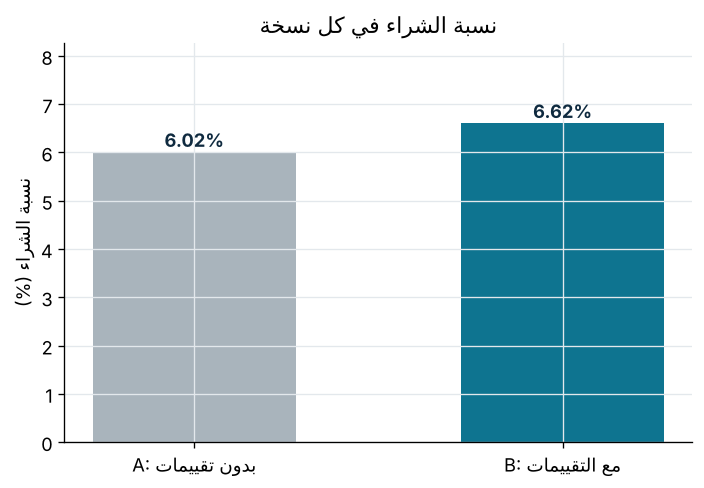

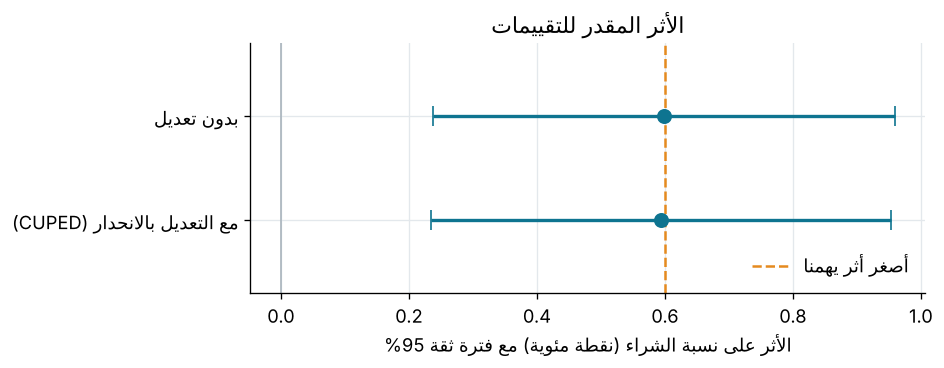

In [12]:
prim, adj = primary(df)
print(f"نسبة الشراء: A={pct(prim['mean_A'])}  B={pct(prim['mean_B'])}")
print(f"الأثر: {pts(prim['diff'])} (فترة الثقة 95%: {prim['ci_low']*100:.2f} إلى {prim['ci_high']*100:.2f})، p={prim['p']:.2g}، زيادة نسبية {prim['relative_lift']:.1%}")
print(f"مع التعديل بالانحدار: {pts(adj['diff'])} ({adj['ci_low']*100:.2f} إلى {adj['ci_high']*100:.2f})، انخفاض التباين {adj['variance_reduction']:.1%}")
conversion_bars(prim, CHARTS_DIR / "01_conversion_by_variant.png")
effect_forest(prim, adj, DESIGN["mde_abs"], CHARTS_DIR / "02_effect_with_ci.png")

<div dir="rtl">

**التفسير:** التقييمات رفعت نسبة الشراء حوالي 0.6 نقطة، والأثر دال لأن فترة الثقة كلها فوق الصفر. التعديل بالانحدار قلل التباين قليلًا فقط (حوالي 1%)، لأن أغلب المستخدمين جدد وليس لهم طلبات سابقة نستفيد منها.

</div>

<div dir="rtl">

### 7.2 المقاييس الثانوية

</div>

In [13]:
sec = secondary(df)
sec

,mean_A,mean_B,diff,ci_low,ci_high,se,p,significant_BH,boot_ci_low,boot_ci_high
metric,,,,,,,,,,
الإيراد لكل مستخدم (ريال),11.1455,12.2162,1.0707,0.3453,1.7961,0.3701,0.0038,True,0.3499,1.8097
قيمة الطلب لمن طلب (ريال),185.2355,184.6629,-0.5726,-5.1138,3.9686,2.3170,0.8048,False,NaN,NaN


<div dir="rtl">

**التفسير:** الإيراد لكل مستخدم ارتفع بشكل دال بعد التصحيح، أما قيمة الطلب فلم تتغير. يعني الزيادة جاءت من أن ناسًا أكثر يشترون، لا من أن المشتري ينفق أكثر.

</div>

<div dir="rtl">

### 7.3 مقاييس الحماية

</div>

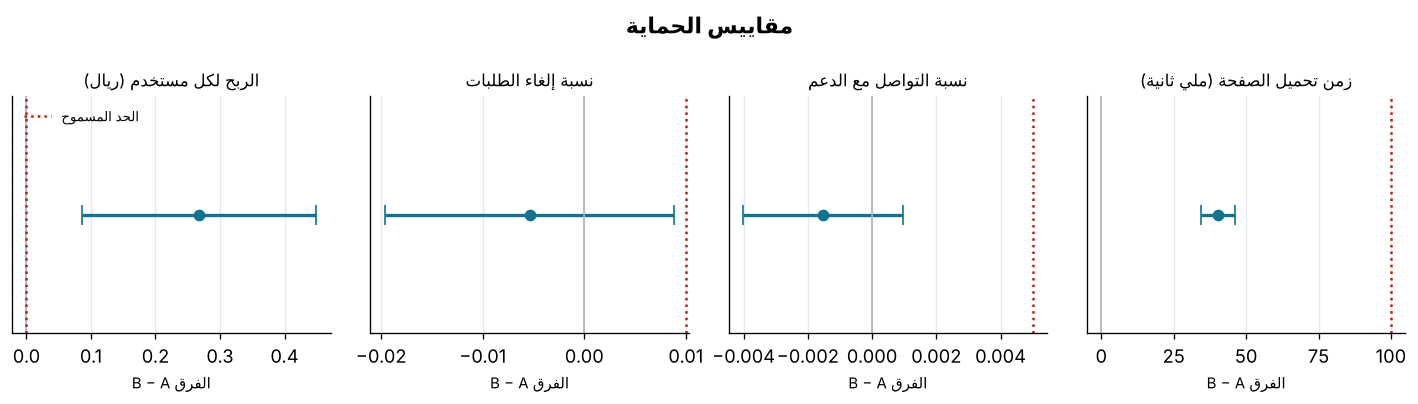

,mean_A,mean_B,diff,ci_low,ci_high,margin,status
metric,,,,,,,
الربح لكل مستخدم (ريال),2.7864,3.0540,0.2677,0.0863,0.4490,0.000,سليم
نسبة إلغاء الطلبات,0.0648,0.0594,-0.0054,-0.0196,0.0089,0.010,سليم
نسبة التواصل مع الدعم,0.0297,0.0282,-0.0015,-0.0040,0.0010,0.005,سليم
زمن تحميل الصفحة (ملي ثانية),1411.8858,1452.1680,40.2823,34.5667,45.9978,100.000,سليم


In [14]:
guard = guardrails(df, GUARDRAILS)
guard_ok = (guard["status"] == "سليم").all()
guardrail_chart(guard, CHARTS_DIR / "04_guardrails.png")
guard[["mean_A", "mean_B", "diff", "ci_low", "ci_high", "margin", "status"]]

<div dir="rtl">

**التفسير:** كل المقاييس ضمن حدودها. زمن التحميل زاد فعلًا حوالي 40 ملي ثانية (فرق دال)، لكنه أقل من الحد المسموح 100 ملي ثانية، فنتابعه بعد الإطلاق.

</div>

<div dir="rtl">

### 7.4 أثر الحداثة والتحليل حسب الجهاز

</div>

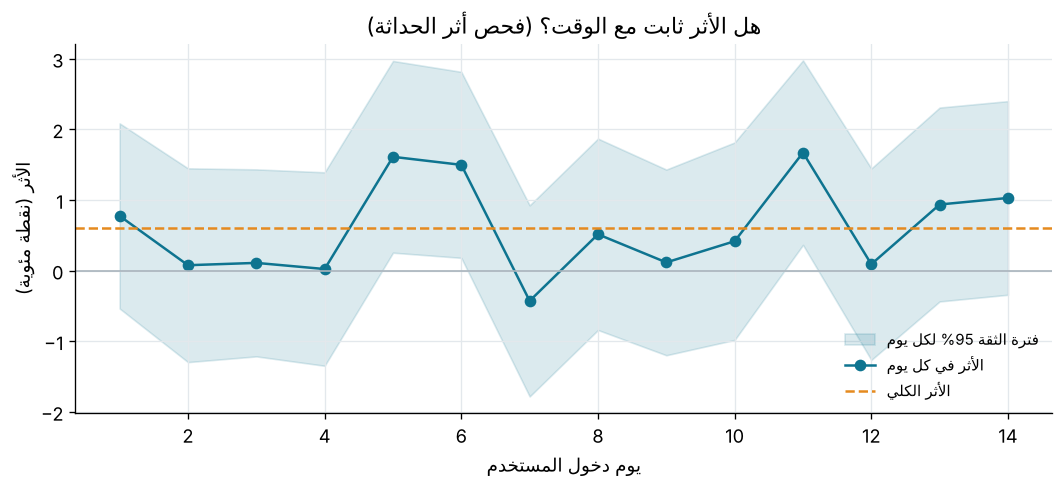

الأسبوع الأول +0.52 نقطة، والثاني +0.68 نقطة، p للفرق بينهما = 0.66


,device,n,mean_A,mean_B,diff,ci_low,ci_high
0,desktop,21056,0.0676,0.0714,0.0038,-0.0031,0.0107
1,mobile,48944,0.0569,0.0639,0.0070,0.0027,0.0112


In [15]:
daily, week = novelty(df)
daily_effect(daily, prim["diff"], CHARTS_DIR / "03_novelty_daily_effect.png")
print(f"الأسبوع الأول {pts(week['week1']['diff'])}، والثاني {pts(week['week2']['diff'])}، p للفرق بينهما = {week['interaction_p']:.2f}")
seg = by_segment(df)
seg[["device", "n", "mean_A", "mean_B", "diff", "ci_low", "ci_high"]]

<div dir="rtl">

**التفسير:** الأثر لم ينخفض في الأسبوع الثاني، فلا دليل على أنه مجرد فضول مؤقت. التحليل حسب الجهاز استكشافي فقط، ولا نبني عليه القرار لأنه لم يكن في خطة التحليل.

</div>

<div dir="rtl">

### 7.5 اختبارات A/A

</div>

500 اختبار A/A: 5.4% نتائج دالة بالصدفة (المتوقع حوالي 5%)


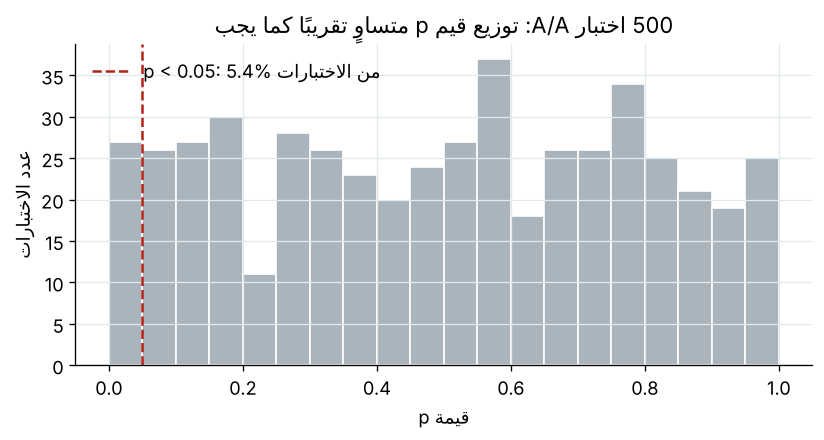

In [16]:
aa = aa_simulation(df)
print(f"{len(aa)} اختبار A/A: {(aa < 0.05).mean():.1%} نتائج دالة بالصدفة (المتوقع حوالي 5%)")
aa_hist(aa, CHARTS_DIR / "05_aa_tests.png")

<div dir="rtl">

## 8. النتائج والقرار

الخلية التالية تجمع النتائج في تقرير، وتحفظ الجداول في `outputs/results`.

</div>

In [17]:
decision, reason = decide(prim["ci_low"], prim["ci_high"], DESIGN["mde_abs"], guard_ok)
profit = guard.loc[GUARDRAILS["profit"]["label"]]
annual = {k: profit[k] * DESIGN["annual_users"] / 1e6 for k in ["diff", "ci_low", "ci_high"]}
rev = sec.loc["الإيراد لكل مستخدم (ريال)"]
guard_rows = "\n".join(f"| {n} | {r['diff']:+.4f} | {r['ci_low']:.4f} إلى {r['ci_high']:.4f} | {r['margin']} | {r['status']} |"
                       for n, r in guard.iterrows())
report = f"""
<div dir="rtl">

### تقرير التجربة: عرض التقييمات بجانب المنتجات

**القرار: {decision}.** {reason}

| البند | القيمة |
|---|---|
| نسبة الشراء | A: {pct(prim['mean_A'])} ← B: {pct(prim['mean_B'])} |
| الأثر | {pts(prim['diff'])} (فترة الثقة 95%: {prim['ci_low']*100:.2f} إلى {prim['ci_high']*100:.2f})، p = {prim['p']:.2g} |
| مع التعديل بالانحدار | {pts(adj['diff'])} ({adj['ci_low']*100:.2f} إلى {adj['ci_high']*100:.2f}) |
| الإيراد لكل مستخدم | {rev['diff']:+.2f} ريال (Bootstrap: {rev['boot_ci_low']:.2f} إلى {rev['boot_ci_high']:.2f}) |
| الربح السنوي التقديري | {annual['diff']:.2f} مليون ريال ({annual['ci_low']:.2f} إلى {annual['ci_high']:.2f}) |
| فحص SRM | p = {s['p']:.3f} ({'سليم' if s['ok'] else 'خلل'}) |

| مقياس الحماية | الفرق | فترة الثقة 95% | الحد | الحالة |
|---|---|---|---|---|
{guard_rows}

</div>
"""
display(Markdown(report))
guard.to_csv(RESULTS_DIR / "guardrails.csv", encoding="utf-8-sig")
sec.to_csv(RESULTS_DIR / "secondary_metrics.csv", encoding="utf-8-sig")
daily.to_csv(RESULTS_DIR / "daily_effect.csv", index=False, encoding="utf-8-sig")


<div dir="rtl">

### تقرير التجربة: عرض التقييمات بجانب المنتجات

**القرار: نطلق.** الأثر إيجابي بثقة 95% وكل مقاييس الحماية ضمن الحدود.

| البند | القيمة |
|---|---|
| نسبة الشراء | A: 6.02% ← B: 6.62% |
| الأثر | +0.60 نقطة (فترة الثقة 95%: 0.24 إلى 0.96)، p = 0.0011 |
| مع التعديل بالانحدار | +0.59 نقطة (0.24 إلى 0.95) |
| الإيراد لكل مستخدم | +1.07 ريال (Bootstrap: 0.35 إلى 1.81) |
| الربح السنوي التقديري | 0.49 مليون ريال (0.16 إلى 0.82) |
| فحص SRM | p = 0.385 (سليم) |

| مقياس الحماية | الفرق | فترة الثقة 95% | الحد | الحالة |
|---|---|---|---|---|
| الربح لكل مستخدم (ريال) | +0.2677 | 0.0863 إلى 0.4490 | 0.0 | سليم |
| نسبة إلغاء الطلبات | -0.0054 | -0.0196 إلى 0.0089 | 0.01 | سليم |
| نسبة التواصل مع الدعم | -0.0015 | -0.0040 إلى 0.0010 | 0.005 | سليم |
| زمن تحميل الصفحة (ملي ثانية) | +40.2823 | 34.5667 إلى 45.9978 | 100.0 | سليم |

</div>


<div dir="rtl">

## 9. التوصية النهائية والقيود

- **التوصية: نطلق عرض التقييمات.** الأثر على نسبة الشراء إيجابي بثقة 95% (حوالي +0.6 نقطة، أي +10% نسبيًا)، والإيراد والربح لكل مستخدم ارتفعا، وكل مقاييس الحماية ضمن حدودها.
- **الخطوة التالية:** إطلاق تدريجي (50% ثم 100%) مع مجموعة holdout صغيرة بدون تقييمات لمدة شهر للتأكد من استمرار الأثر، ومتابعة زمن التحميل.
- **القيود:**
  - البيانات من محاكاة، والأثر الحقيقي المفترض (0.7 نقطة) يقع داخل فترة الثقة.
  - الحد الأدنى للفترة (0.24) أقل من 0.6، فلا نستبعد أن يكون الأثر أصغر مما يهمنا تجاريًا.
  - أسبوعان لا يمثلان المواسم مثل رمضان والجمعة البيضاء.
  - لم نقس أثر التقييمات السلبية على منتجات بعينها.

</div>